# Step 5b: Momentum with the model v without
- **Without model (raw):** runs in the last 10 balls, minus 6 per wicket. What a scoreboard or commentator sees.
- **With model:** last 10 balls of actual value minus expected value (Step 5).

All 2022-2026 balls (out-of-sample predictions). Both are standardised (z-scores) so they can share a chart.

In [1]:
import os, warnings; warnings.filterwarnings('ignore'); ROOT=os.path.expanduser('~/hundred-momentum')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
d = pd.read_csv(ROOT+'/data/clean/momentum.csv', parse_dates=['date']); M = pd.read_parquet(ROOT+'/data/clean/matches.parquet')
d = d.sort_values(['date','match_id','innings','seq']).reset_index(drop=True); g = d.groupby(['match_id','innings'], sort=False)
d['raw_value'] = np.where(d.is_wicket == 1, -6, d.runs_total)
d['raw_momentum'] = g.raw_value.transform(lambda x: x.rolling(10, min_periods=1).sum())
d['model_momentum'] = d.momentum
for c_ in ('raw_momentum', 'model_momentum'): d[c_ + '_z'] = d.groupby('innings')[c_].transform(lambda x: (x - x.mean()) / x.std())
d['phase'] = np.select([d.ball_no <= 25, d.ball_no <= 75], ['1 powerplay', '2 middle'], '3 death')
print(d.shape)

(31732, 35)


## 1. Does the measure just follow the match situation?
A fair momentum measure should average about zero in every phase and state. If it rises or falls with the phase, it is measuring the situation, not momentum.

In [2]:
# situation at the START of each 10-ball window (wickets inside the window would otherwise count on both sides)
d['wkts_start'] = g.wkts_pre.shift(10); d['wp_start'] = g.wp_pre.shift(10)
full = d[d.ball_no >= 11].dropna(subset=['wkts_start'])   # full 10-ball windows only
tab = full.groupby(['innings','phase'])[['raw_momentum_z','model_momentum_z']].mean().round(3); print(tab)
st = full.assign(wkts=np.minimum(full.wkts_start, 6).astype(int)).groupby(['innings','wkts'])[['raw_momentum_z','model_momentum_z']].mean().round(3); print(st)
rho = lambda a, b: spearmanr(a, b, nan_policy='omit').correlation
for i in (1, 2):
    z = full[full.innings == i]
    print(f"innings {i}: Spearman with ball number  raw {rho(z.raw_momentum, z.ball_no):+.3f}  model {rho(z.model_momentum, z.ball_no):+.3f} | with wickets down at window start  raw {rho(z.raw_momentum, z.wkts_start):+.3f}  model {rho(z.model_momentum, z.wkts_start):+.3f}" + (f" | with chase win chance at start  raw {rho(z.raw_momentum, z.wp_start):+.3f}  model {rho(z.model_momentum, z.wp_start):+.3f}" if i == 2 else "") + f"")

                     raw_momentum_z  model_momentum_z
innings phase                                        
1       1 powerplay           0.141             0.043
        2 middle              0.008            -0.046
        3 death               0.167             0.092
2       1 powerplay           0.146            -0.044
        2 middle              0.051             0.019
        3 death               0.027            -0.045
              raw_momentum_z  model_momentum_z
innings wkts                                  
1       0              0.214             0.116
        1              0.055            -0.042
        2              0.087             0.038
        3              0.053            -0.016
        4             -0.029            -0.085
        5              0.014            -0.022
        6             -0.030            -0.011
2       0              0.145            -0.070
        1              0.018            -0.002
        2              0.076             0.044
    

## 2. Does it carry forward?
Non-overlapping 10-ball windows. Each measure's last 10 balls v the next 10 balls of the SAME measure, and v the next 10 balls of over-performance (actual - expected), which removes the situation. Interval: resampling whole matches.

In [3]:
rows = []
for (mid, inn), x in g:
    for s in range(10, len(x) - 9, 10):
        rows.append(dict(match_id=mid, innings=inn, season=x.season.iloc[0], raw_past=x.raw_value.values[s-10:s].sum(), raw_future=x.raw_value.values[s:s+10].sum(),
                         gap_past=x.value_gap.values[s-10:s].sum(), gap_future=x.value_gap.values[s:s+10].sum(), ball=s))
W = pd.DataFrame(rows); rng = np.random.default_rng(5)
def ci(f, z):
    um = z.match_id.unique(); pos = {q: np.where(z.match_id.values == q)[0] for q in um}; z = z.reset_index(drop=True)
    return np.percentile([f(z.iloc[np.concatenate([pos[q] for q in rng.choice(um, len(um))])]) for _ in range(1000)], [2.5, 97.5])
out = []
for i in (1, 2):
    z = W[W.innings == i]
    for nm, a, b in [('raw -> raw future', 'raw_past', 'raw_future'), ('raw -> future over-performance', 'raw_past', 'gap_future'), ('model -> future over-performance', 'gap_past', 'gap_future')]:
        f = lambda q, a=a, b=b: spearmanr(q[a], q[b]).correlation; lo, hi = ci(f, z); out.append(dict(innings=i, test=nm, spearman=f(z), lo=lo, hi=hi, windows=len(z)))
P = pd.DataFrame(out); print(P.round(3).to_string(index=False))
# raw persistence after removing the phase: correlate within the same window position
for i in (1, 2):
    z = W[W.innings == i]; r = z.groupby('ball').apply(lambda q: spearmanr(q.raw_past, q.raw_future).correlation if len(q) > 30 else np.nan)
    print(f'innings {i}: raw -> raw within the same stage of the innings, mean Spearman {r.mean():+.3f}  (by window start: {r.round(3).to_dict()})')

 innings                             test  spearman     lo    hi  windows
       1                raw -> raw future     0.118  0.063 0.171     1425
       1   raw -> future over-performance     0.065  0.006 0.121     1425
       1 model -> future over-performance     0.074  0.016 0.134     1425
       2                raw -> raw future     0.063  0.013 0.108     1296
       2   raw -> future over-performance    -0.026 -0.081 0.023     1296
       2 model -> future over-performance     0.076  0.010 0.145     1296
innings 1: raw -> raw within the same stage of the innings, mean Spearman +0.119  (by window start: {10: 0.106, 20: 0.24, 30: 0.153, 40: -0.024, 50: 0.066, 60: 0.023, 70: 0.282, 80: 0.038, 90: 0.183, 100: nan})
innings 2: raw -> raw within the same stage of the innings, mean Spearman +0.055  (by window start: {10: 0.078, 20: 0.028, 30: 0.046, 40: 0.018, 50: -0.038, 60: 0.213, 70: 0.082, 80: 0.118, 90: -0.046, 100: nan})


## 3. How often do they disagree?

In [4]:
for i in (1, 2):
    z = full[full.innings == i]; s1, s2 = np.sign(z.raw_momentum_z), np.sign(z.model_momentum_z)
    print(f'innings {i}: Spearman between the two {rho(z.raw_momentum, z.model_momentum):+.3f}; opposite signs on {np.mean(s1 != s2):.0%} of balls; '
          f'raw says strong (top 20%) but model says below expected: {np.mean((z.raw_momentum_z > z.raw_momentum_z.quantile(.8)) & (z.model_momentum_z < 0)) / .2:.0%} of raw-strong balls')

innings 1: Spearman between the two +0.922; opposite signs on 11% of balls; raw says strong (top 20%) but model says below expected: 0% of raw-strong balls
innings 2: Spearman between the two +0.656; opposite signs on 24% of balls; raw says strong (top 20%) but model says below expected: 4% of raw-strong balls


## 4. Charts

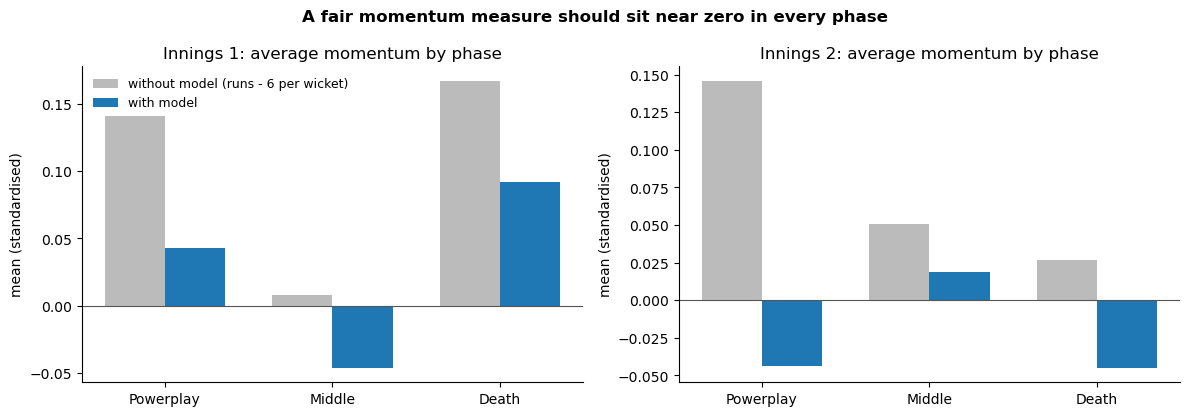

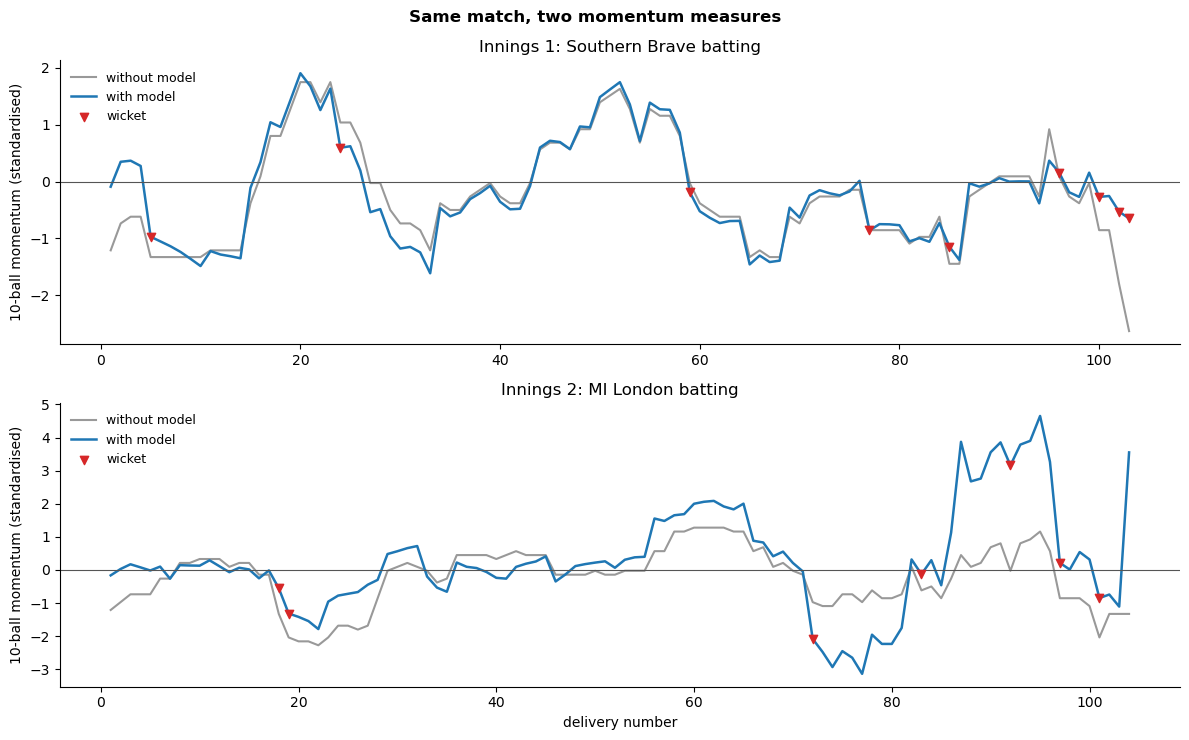

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, i in zip(ax, (1, 2)):
    t = tab.loc[i]; x = np.arange(3); a.bar(x - .18, t.raw_momentum_z, .36, label='without model (runs - 6 per wicket)', color='#bbbbbb'); a.bar(x + .18, t.model_momentum_z, .36, label='with model', color='#1f77b4')
    a.set_xticks(x, ['Powerplay', 'Middle', 'Death']); a.axhline(0, color='#555', lw=.8); a.set_title(f'Innings {i}: average momentum by phase'); a.set_ylabel('mean (standardised)'); a.spines[['top','right']].set_visible(False)
ax[0].legend(frameon=False, fontsize=9); fig.suptitle('A fair momentum measure should sit near zero in every phase', fontweight='bold'); fig.tight_layout(); fig.savefig(ROOT+'/figures/momentum_bias_by_phase.png', dpi=150); plt.show()
x = d[d.match_id.astype(str) == str(d[(d.season == 2026) & (d.batting_team == 'Southern Brave') & (d.bowling_team == 'MI London')].match_id.iloc[0])]
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5))
for a, i in zip(ax, (1, 2)):
    z = x[x.innings == i]; bn = np.arange(1, len(z) + 1)
    a.plot(bn, z.raw_momentum_z, color='#999', lw=1.5, label='without model'); a.plot(bn, z.model_momentum_z, color='#1f77b4', lw=1.8, label='with model'); a.axhline(0, color='#555', lw=.8)
    a.scatter(bn[(z.is_wicket == 1).values], z.model_momentum_z[(z.is_wicket == 1).values], marker='v', color='#d62728', zorder=3, label='wicket')
    a.set_title(f'Innings {i}: {z.batting_team.iloc[0]} batting'); a.set_ylabel('10-ball momentum (standardised)'); a.legend(frameon=False, loc='upper left', fontsize=9); a.spines[['top','right']].set_visible(False)
ax[1].set_xlabel('delivery number'); fig.suptitle('Same match, two momentum measures', fontweight='bold'); fig.tight_layout(); fig.savefig(ROOT+'/figures/momentum_with_vs_without_model.png', dpi=150); plt.show()